# DermKG: a concept-centric dermatology knowledge graph (SkinCon)

Builds an instance-level heterogeneous knowledge graph from SkinCon concept annotations and Fitzpatrick17k labels. No images are needed.

**Schema: 8 node types**

| Node type | Count | Meaning |
|---|---|---|
| SkinImage | 3,230 | one annotated clinical image (md5, split, skin type) |
| Concept | 48 | dermatologist-annotated morphological descriptor |
| ConceptGroup | 5 | primary lesion, secondary change, color, shape/surface, vascular pattern |
| Disease | 113 | skin condition label |
| DiseaseCategory | 9 | Fitzpatrick17k nine-partition label |
| SuperCategory | 3 | benign, malignant, non-neoplastic |
| SkinType | 7 | Fitzpatrick I to VI, plus unknown |
| ClinicalRule | 20 expert (+ optional mined) | morphology to diagnosis rule |

**11 relation types**

- Structural (read directly from annotations): `HAS_CONCEPT`, `HAS_SKIN_TYPE`, `DIAGNOSED_AS`, `BELONGS_TO`, `IS_A`, `SUBCLASS_OF`
- Knowledge / inference: `CHARACTERIZED_BY` (disease to concept), `CO_OCCURS` (concept to concept), `GOVERNED_BY` (concept to rule), `INDICATES` (rule to disease or category), `ACTIVATES` (image to rule)

**Leakage control.** Everything that uses labels (disease concept profiles, co-occurrence, rule strength, mined rules) is computed on the **training split only**. `DIAGNOSED_AS` edges of val/test images are excluded from the inference graph and exported separately as labels.

In [ ]:
# %pip install pandas numpy networkx matplotlib pyvis -i https://pypi.tuna.tsinghua.edu.cn/simple

## 1. Config

In [1]:
SKINCON_CSV = "image.csv"
F17K_CSV = "fitzpatrick17k.csv"
OUT_DIR = "data/dermkg"
SEED = 42
SPLIT = (0.7, 0.1, 0.2)        # train / val / test, stratified by disease

# disease -> concept profile (CHARACTERIZED_BY)
SMOOTH_ALPHA = 5.0             # shrink P(c|d) toward global prior P(c) for small classes
EDGE_MIN_PROB = 0.20           # frequent concept in this disease
EDGE_MIN_LIFT = 1.0
DISTINCT_MIN_LIFT = 3.0        # or: rare overall but strongly enriched in this disease
DISTINCT_MIN_COUNT = 3
EDGE_MIN_COUNT = 2

# concept co-occurrence (CO_OCCURS)
PMI_MIN = 0.5
COOC_MIN_COUNT = 10

# rule strength from training-split validation
STRONG_LIFT, STRONG_SUPPORT = 5.0, 10
MODERATE_LIFT = 2.0
RULE_WEIGHT = {"strong": 3, "moderate": 2, "weak": 1, "unsupported": 0}

# optional data-mined rules (train split only)
INCLUDE_MINED_RULES = True
MINED_TOPK_PER_DISEASE = 1
MINED_MIN_SUPPORT = 5          # images of the target disease that satisfy the premise
MINED_MIN_PRECISION = 0.30     # P(disease | premise) on train
MINED_MIN_LIFT = 5.0

## 2. Imports

In [2]:
import os, json, itertools
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from pyvis.network import Network

os.makedirs(OUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

## 3. Data parsing

SkinCon `ImageID` without `.jpg` equals Fitzpatrick17k `md5hash`. Images flagged "Do not consider" by the dermatologists are removed.

In [3]:
sk = pd.read_csv(SKINCON_CSV).drop(columns=["Unnamed: 0"], errors="ignore")
n_raw = len(sk)
sk = sk[sk["Do not consider this image"] == 0].drop(columns=["Do not consider this image"])
sk["md5"] = sk["ImageID"].str.replace(".jpg", "", regex=False)
CONCEPTS = [c for c in sk.columns if c not in ("ImageID", "md5")]

f17k = pd.read_csv(F17K_CSV)
df = sk.merge(f17k, left_on="md5", right_on="md5hash", how="inner").reset_index(drop=True)
df["skin_type"] = df["fitzpatrick_scale"].map(lambda v: f"FST-{int(v)}" if v in range(1, 7) else "FST-unknown")
DISEASES = sorted(df["label"].unique())
CATEGORIES = sorted(df["nine_partition_label"].unique())
SUPERS = sorted(df["three_partition_label"].unique())
D2CAT = df.groupby("label")["nine_partition_label"].first().to_dict()
CAT2SUP = df.groupby("nine_partition_label")["three_partition_label"].first().to_dict()

print(f"raw {n_raw} -> usable {len(df)} images | {len(DISEASES)} diseases | {len(CONCEPTS)} concepts")
print(f"concepts per image: mean {df[CONCEPTS].sum(axis=1).mean():.2f}, images with 0 concepts: {(df[CONCEPTS].sum(axis=1) == 0).sum()}")

raw 3690 -> usable 3230 images | 113 diseases | 48 concepts
concepts per image: mean 3.11, images with 0 concepts: 0


## 4. Concept groups (dermatological lexicon)

The 48 SkinCon concepts are organized following the standard clinical description order: primary lesion, secondary change, color, shape/surface, vascular pattern.

In [4]:
CONCEPT_GROUPS = {
    "primary_lesion": ["Macule", "Patch", "Papule", "Plaque", "Nodule", "Vesicle", "Bulla", "Pustule",
                       "Wheal", "Cyst", "Abscess", "Comedo", "Burrow"],
    "secondary_change": ["Scale", "Crust", "Erosion", "Ulcer", "Excoriation", "Fissure", "Atrophy", "Scar",
                         "Lichenification", "Xerosis", "Exudate", "Sclerosis", "Induration", "Friable"],
    "color": ["Erythema", "Brown(Hyperpigmentation)", "White(Hypopigmentation)", "Purple", "Yellow", "Black",
              "Blue", "Gray", "Salmon", "Pigmented", "Translucent"],
    "shape_surface": ["Dome-shaped", "Flat topped", "Pedunculated", "Exophytic/Fungating",
                      "Warty/Papillomatous", "Umbilicated", "Acuminate"],
    "vascular_pattern": ["Telangiectasia", "Purpura/Petechiae", "Poikiloderma"],
}
C2GROUP = {c: g for g, cs in CONCEPT_GROUPS.items() for c in cs}
assert set(C2GROUP) == set(CONCEPTS), set(CONCEPTS) ^ set(C2GROUP)
pd.Series(C2GROUP).value_counts()

secondary_change    14
primary_lesion      13
color               11
shape_surface        7
vascular_pattern     3
Name: count, dtype: int64

## 5. Stratified split

Per-disease split so every class with at least 3 images appears in train, val and test. Classes with fewer than 3 images go to train.

In [5]:
split = pd.Series("train", index=df.index)
for d, idx in df.groupby("label").groups.items():
    idx = rng.permutation(np.array(idx))
    n = len(idx)
    if n < 3:
        continue
    n_te = max(1, int(round(n * SPLIT[2])))
    n_va = max(1, int(round(n * SPLIT[1])))
    split[idx[:n_te]] = "test"
    split[idx[n_te:n_te + n_va]] = "val"
df["split"] = split
df[["md5", "label", "split"]].to_csv(os.path.join(OUT_DIR, "split.csv"), index=False)

TR = df[df["split"] == "train"]
print(df["split"].value_counts().to_string())
print("diseases in train / val / test:", TR["label"].nunique(),
      df.loc[df.split == "val", "label"].nunique(), df.loc[df.split == "test", "label"].nunique())

split
train    2259
test      647
val       324
diseases in train / val / test: 113 112 112


## 6. Statistical analysis (training split)

Concept prevalence per disease is shrunk toward the global prior to stabilize small classes:

$$\hat P(c\mid d)=\frac{n_{dc}+\alpha P(c)}{n_d+\alpha},\qquad \mathrm{lift}(c,d)=\frac{\hat P(c\mid d)}{P(c)}$$

Top concepts by super-category (train):
  benign          Papule 0.46, Erythema 0.46, Plaque 0.42, Brown(Hyperpigmentation) 0.35, Scale 0.21
  malignant       Erythema 0.66, Plaque 0.57, Papule 0.37, Crust 0.33, Brown(Hyperpigmentation) 0.32
  non-neoplastic  Erythema 0.71, Plaque 0.65, Papule 0.35, Scale 0.24, Brown(Hyperpigmentation) 0.19


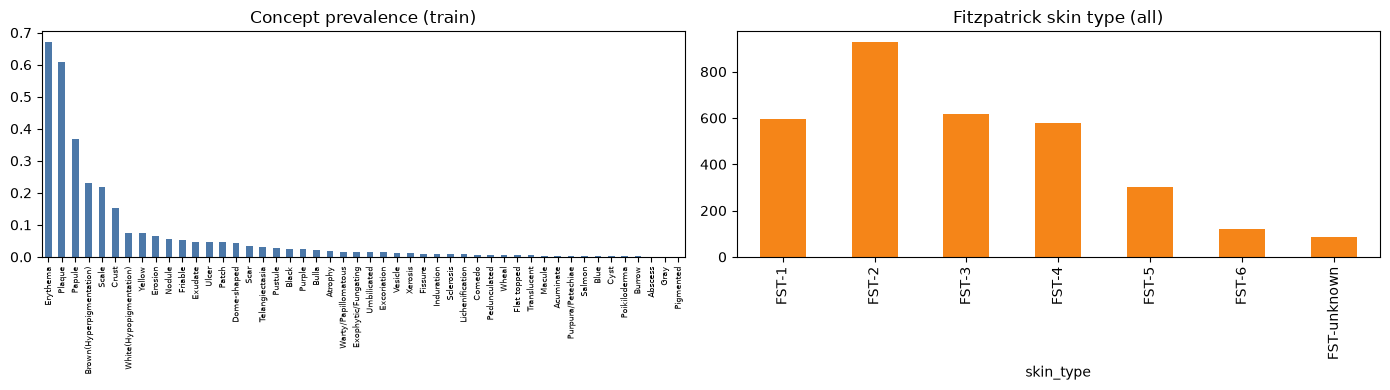

In [6]:
Xtr = TR[CONCEPTS].astype(int)
p_c = Xtr.mean()
n_d = TR.groupby("label").size().reindex(DISEASES).fillna(0)
n_dc = Xtr.groupby(TR["label"]).sum().reindex(DISEASES).fillna(0)
p_dc = (n_dc + SMOOTH_ALPHA * p_c).div(n_d + SMOOTH_ALPHA, axis=0)
lift_dc = p_dc.div(p_c.replace(0, np.nan), axis=1).fillna(0)
p_dc.round(4).to_csv(os.path.join(OUT_DIR, "disease_concept_prob_train.csv"))

# concept prevalence by super-category
prev = Xtr.groupby(TR["three_partition_label"]).mean().T
prev["group"] = prev.index.map(C2GROUP)
print("Top concepts by super-category (train):")
for s in SUPERS:
    print(f"  {s:15s}", ", ".join(f"{c} {v:.2f}" for c, v in prev[s].sort_values(ascending=False).head(5).items()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
p_c.sort_values(ascending=False).plot.bar(ax=axes[0], color="#4c78a8", title="Concept prevalence (train)")
axes[0].tick_params(axis="x", labelsize=6)
df["skin_type"].value_counts().sort_index().plot.bar(ax=axes[1], color="#f58518", title="Fitzpatrick skin type (all)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "concept_skin_type_stats.png"), dpi=200); plt.show()

## 7. Clinical rule encoding

20 expert rules from standard dermatological morphology. A premise is a conjunction of clauses, each clause a disjunction of concepts (e.g. `[[Telangiectasia], [Papule, Nodule]]` means Telangiectasia AND (Papule OR Nodule)). A rule indicates a set of diseases or a disease category.

Rule **strength** is assigned by validating the rule on the training split, mirroring the strong / moderate / weak scheme:

$$\mathrm{precision}=P(y\in T\mid \text{premise}),\quad \mathrm{lift}=\frac{\mathrm{precision}}{P(y\in T)}$$

strong: lift at least 5 with support at least 10; moderate: lift at least 2; weak: lift at least 1; otherwise unsupported (kept as a node but given zero weight).

In [7]:
BCC = ["basal cell carcinoma", "basal cell carcinoma morpheiform", "solid cystic basal cell carcinoma"]
EXPERT_RULES = [
    # id, name, premise (AND of OR-clauses), target diseases, target categories
    ("R01", "Pearly papule with telangiectasia -> BCC", [["Telangiectasia"], ["Papule", "Nodule"]], BCC, []),
    ("R02", "Translucent papule/nodule -> BCC", [["Translucent"], ["Papule", "Nodule"]], BCC, []),
    ("R03", "Burrow -> scabies", [["Burrow"]], ["scabies"], []),
    ("R04", "Wheal -> urticarial disease", [["Wheal"]], ["urticaria", "urticaria pigmentosa"], []),
    ("R05", "Comedo -> comedonal disease", [["Comedo"]], ["acne", "acne vulgaris", "naevus comedonicus"], []),
    ("R06", "Depigmented macule/patch -> depigmentation disorder", [["White(Hypopigmentation)"], ["Macule", "Patch"]],
     ["vitiligo", "halo nevus"], []),
    ("R07", "Black/blue/gray pigmented lesion -> melanocytic lesion", [["Black", "Blue", "Gray"]], [],
     ["benign melanocyte", "malignant melanoma"]),
    ("R08", "Erythematous scaly plaque -> papulosquamous disease", [["Erythema"], ["Scale"], ["Plaque"]],
     ["psoriasis", "pityriasis rosea", "pityriasis rubra pilaris", "seborrheic dermatitis", "mycosis fungoides"], []),
    ("R09", "Pustule -> pustular / follicular disease", [["Pustule"]],
     ["pustular psoriasis", "folliculitis", "acne", "acne vulgaris", "rosacea", "perioral dermatitis"], []),
    ("R10", "Vesicle or bulla -> vesiculobullous disease", [["Vesicle", "Bulla"]],
     ["acquired autoimmune bullous diseaseherpes gestationis", "epidermolysis bullosa", "hailey hailey disease",
      "dyshidrotic eczema", "allergic contact dermatitis", "stevens johnson syndrome", "porphyria",
      "erythema multiforme"], []),
    ("R11", "Warty/papillomatous lesion -> verrucous epidermal lesion", [["Warty/Papillomatous"]],
     ["seborrheic keratosis", "epidermal nevus", "nevus sebaceous of jadassohn"], []),
    ("R12", "Ulcerated or fungating nodule -> malignant epidermal tumor",
     [["Ulcer", "Exophytic/Fungating"], ["Nodule", "Plaque"]], [], ["malignant epidermal"]),
    ("R13", "Friable erythematous papule/nodule -> pyogenic granuloma", [["Friable"], ["Papule", "Nodule"]],
     ["pyogenic granuloma", "granuloma pyogenic"], []),
    ("R14", "Scar-like nodule/plaque -> keloid", [["Scar"], ["Nodule", "Plaque"]], ["keloid"], []),
    ("R15", "Purple flat-topped papule -> lichen planus", [["Purple"], ["Flat topped"], ["Papule"]],
     ["lichen planus"], []),
    ("R16", "Violaceous plaque/nodule/patch -> vascular tumor or malformation", [["Purple"], ["Plaque", "Nodule", "Patch"]],
     ["kaposi sarcoma", "port wine stain"], []),
    ("R17", "Lichenification or excoriation -> chronic pruritic dermatosis", [["Lichenification", "Excoriation"]],
     ["lichen simplex", "neurodermatitis", "prurigo nodularis", "neurotic excoriations", "eczema", "scabies"], []),
    ("R18", "Yellow papule/plaque -> lipid or xanthomatous lesion", [["Yellow"], ["Papule", "Plaque"]],
     ["xanthomas", "juvenile xanthogranuloma", "necrobiosis lipoidica", "nevus sebaceous of jadassohn"], []),
    ("R19", "Sclerosis or induration -> sclerosing dermatosis", [["Sclerosis", "Induration"]],
     ["scleroderma", "scleromyxedema", "necrobiosis lipoidica", "basal cell carcinoma morpheiform"], []),
    ("R20", "Atrophy -> atrophic dermatosis", [["Atrophy"]],
     ["striae", "aplasia cutis", "necrobiosis lipoidica", "lupus erythematosus"], []),
]
for r in EXPERT_RULES:   # vocabulary check
    assert all(c in CONCEPTS for cl in r[2] for c in cl), r[0]
    assert all(d in DISEASES for d in r[3]) and all(c in CATEGORIES for c in r[4]), r[0]


def premise_mask(frame, premise):
    m = np.ones(len(frame), dtype=bool)
    for clause in premise:
        m &= frame[clause].astype(int).sum(axis=1).values > 0
    return m


def target_diseases(t_dis, t_cat):
    return sorted(set(t_dis) | {d for d in DISEASES if D2CAT[d] in t_cat})


def validate_rule(premise, targets, frame):
    m = premise_mask(frame, premise)
    y = frame["label"].isin(targets).values
    sup = int(m.sum())
    prec = y[m].mean() if sup else 0.0
    base = y.mean()
    lift = prec / base if base > 0 else 0.0
    if lift >= STRONG_LIFT and sup >= STRONG_SUPPORT:
        s = "strong"
    elif lift >= MODERATE_LIFT:
        s = "moderate"
    elif lift >= 1.0 and sup > 0:
        s = "weak"
    else:
        s = "unsupported"
    return dict(support=sup, precision=round(prec, 3), recall=round(m[y].mean() if y.sum() else 0, 3),
                lift=round(lift, 2), strength=s)


RULES = []
for rid, name, prem, t_dis, t_cat in EXPERT_RULES:
    tg = target_diseases(t_dis, t_cat)
    RULES.append(dict(rule_id=rid, name=name, origin="expert", premise=prem, target_diseases=t_dis,
                      target_categories=t_cat, targets=tg, **validate_rule(prem, tg, TR)))
rules_df = pd.DataFrame(RULES)
rules_df[["rule_id", "name", "support", "precision", "recall", "lift", "strength"]]

,rule_id,name,support,precision,recall,lift,strength
0,R01,Pearly papule with telangiectasia -> BCC,36,0.472,0.170,10.67,strong
1,R02,Translucent papule/nodule -> BCC,4,1.000,0.040,22.59,moderate
2,R03,Burrow -> scabies,3,0.333,0.017,12.76,moderate
3,R04,Wheal -> urticarial disease,15,0.733,0.282,42.48,strong
4,R05,Comedo -> comedonal disease,16,0.750,0.128,18.02,strong
5,R06,Depigmented macule/patch -> depigmentation dis...,39,0.744,0.806,46.66,strong
6,R07,Black/blue/gray pigmented lesion -> melanocyti...,65,0.415,0.245,8.53,strong
7,R08,Erythematous scaly plaque -> papulosquamous di...,290,0.303,0.447,3.48,moderate
8,R09,Pustule -> pustular / follicular disease,65,0.615,0.252,8.74,strong
9,R10,Vesicle or bulla -> vesiculobullous disease,70,0.414,0.159,5.14,strong


### 7.1 Optional: data-mined rules

For long-tail diseases that no expert rule covers, mine 1 or 2 concept premises on the training split that are strongly enriched for that disease. Kept as `origin = mined` so the two sources can be ablated separately.

In [8]:
if INCLUDE_MINED_RULES:
    Xb = Xtr.values.astype(bool)
    y = TR["label"].values
    cand = [(c,) for c in CONCEPTS] + list(itertools.combinations(CONCEPTS, 2))
    cidx = {c: i for i, c in enumerate(CONCEPTS)}
    masks = {p: Xb[:, [cidx[c] for c in p]].all(1) for p in cand}
    mined, k = [], 0
    for d in DISEASES:
        yd = y == d
        base = yd.mean()
        if base == 0:
            continue
        scored = []
        for p, m in masks.items():
            hit = int((m & yd).sum())
            if hit < MINED_MIN_SUPPORT:
                continue
            prec = hit / m.sum()
            lift = prec / base
            if lift >= MINED_MIN_LIFT and prec >= MINED_MIN_PRECISION:
                scored.append((lift, hit, prec, p))
        for lift, hit, prec, p in sorted(scored, reverse=True)[:MINED_TOPK_PER_DISEASE]:
            k += 1
            prem = [[c] for c in p]
            RULES.append(dict(rule_id=f"M{k:03d}", name=f"{' + '.join(p)} -> {d}", origin="mined", premise=prem,
                              target_diseases=[d], target_categories=[], targets=[d],
                              **validate_rule(prem, [d], TR)))
    rules_df = pd.DataFrame(RULES)
    print(f"mined rules: {k} covering {rules_df.loc[rules_df.origin=='mined','targets'].str[0].nunique()} diseases")

print(rules_df.groupby(["origin", "strength"]).size().unstack(fill_value=0))
rules_df.drop(columns=["premise"]).assign(premise=rules_df["premise"].map(json.dumps)).to_csv(
    os.path.join(OUT_DIR, "clinical_rules.csv"), index=False)

mined rules: 17 covering 17 diseases
strength  moderate  strong
origin                    
expert           5      15
mined            5      12


## 8. Graph construction

In [9]:
G = nx.MultiDiGraph()
ADD = G.add_edge

# ---- nodes
for c in CONCEPTS:
    G.add_node(f"Concept:{c}", ntype="Concept", name=c, group=C2GROUP[c], prior=float(p_c[c]))
for g in CONCEPT_GROUPS:
    G.add_node(f"Group:{g}", ntype="ConceptGroup", name=g)
for d in DISEASES:
    G.add_node(f"Disease:{d}", ntype="Disease", name=d, category=D2CAT[d], n_train=int(n_d[d]))
for c in CATEGORIES:
    G.add_node(f"Category:{c}", ntype="DiseaseCategory", name=c)
for s in SUPERS:
    G.add_node(f"Super:{s}", ntype="SuperCategory", name=s)
for t in sorted(df["skin_type"].unique()):
    G.add_node(f"SkinType:{t}", ntype="SkinType", name=t)
for r in RULES:
    G.add_node(f"Rule:{r['rule_id']}", ntype="ClinicalRule", name=r["name"], origin=r["origin"],
               strength=r["strength"], weight=RULE_WEIGHT[r["strength"]], lift=r["lift"], support=r["support"])
for r in df.itertuples():
    G.add_node(f"Image:{r.md5}", ntype="SkinImage", name=r.md5[:8], split=r.split, skin_type=r.skin_type)

# ---- structural edges
for r in df.itertuples():
    img = f"Image:{r.md5}"
    ADD(img, f"SkinType:{r.skin_type}", rel="HAS_SKIN_TYPE", weight=1.0)
    ADD(img, f"Disease:{r.label}", rel="DIAGNOSED_AS", weight=1.0, split=r.split)
xa = df[CONCEPTS].values.astype(bool)
for i, m in enumerate(df["md5"]):
    for j in np.flatnonzero(xa[i]):
        ADD(f"Image:{m}", f"Concept:{CONCEPTS[j]}", rel="HAS_CONCEPT", weight=1.0)
for c, g in C2GROUP.items():
    ADD(f"Concept:{c}", f"Group:{g}", rel="BELONGS_TO", weight=1.0)
for d, c in D2CAT.items():
    ADD(f"Disease:{d}", f"Category:{c}", rel="IS_A", weight=1.0)
for c, s in CAT2SUP.items():
    ADD(f"Category:{c}", f"Super:{s}", rel="SUBCLASS_OF", weight=1.0)

# ---- knowledge edges (train statistics only)
for d in DISEASES:
    for c in CONCEPTS:
        p, cnt, lf = p_dc.at[d, c], n_dc.at[d, c], lift_dc.at[d, c]
        common = p >= EDGE_MIN_PROB and lf >= EDGE_MIN_LIFT
        distinct = lf >= DISTINCT_MIN_LIFT and cnt >= DISTINCT_MIN_COUNT
        if cnt >= EDGE_MIN_COUNT and (common or distinct):
            ADD(f"Disease:{d}", f"Concept:{c}", rel="CHARACTERIZED_BY", weight=float(p), lift=float(lf), count=int(cnt))

Xa = Xtr.values.astype(float); N = len(Xa)
co = Xa.T @ Xa; pc = co.diagonal() / N
for i, j in itertools.combinations(range(len(CONCEPTS)), 2):
    if co[i, j] >= COOC_MIN_COUNT:
        pmi = float(np.log((co[i, j] / N) / (pc[i] * pc[j])))
        if pmi >= PMI_MIN:
            for a, b in ((i, j), (j, i)):
                ADD(f"Concept:{CONCEPTS[a]}", f"Concept:{CONCEPTS[b]}", rel="CO_OCCURS", weight=pmi, count=int(co[i, j]))

# ---- rule edges
for r in RULES:
    rn = f"Rule:{r['rule_id']}"
    for k, clause in enumerate(r["premise"]):
        for c in clause:
            ADD(f"Concept:{c}", rn, rel="GOVERNED_BY", weight=1.0, clause=k)
    for d in r["target_diseases"]:
        ADD(rn, f"Disease:{d}", rel="INDICATES", weight=float(RULE_WEIGHT[r["strength"]]))
    for c in r["target_categories"]:
        ADD(rn, f"Category:{c}", rel="INDICATES", weight=float(RULE_WEIGHT[r["strength"]]))

# ACTIVATES depends only on the image's concepts (inputs), so it is computed for every split
ACT = np.zeros((len(df), len(RULES)), dtype=bool)
for k, r in enumerate(RULES):
    ACT[:, k] = premise_mask(df, r["premise"])
    for i in np.flatnonzero(ACT[:, k]):
        ADD(f"Image:{df.at[i, 'md5']}", f"Rule:{r['rule_id']}", rel="ACTIVATES", weight=float(RULE_WEIGHT[r["strength"]]))

print(G)

MultiDiGraph with 3452 nodes and 19365 edges


## 9. Graph statistics

,DermKG
nodes,3452.000000
edges,19365.000000
node types,8.000000
relation types,11.000000
expert rules,20.000000
mined rules,17.000000
density,0.001626
LCC ratio,1.000000
avg degree,11.219583


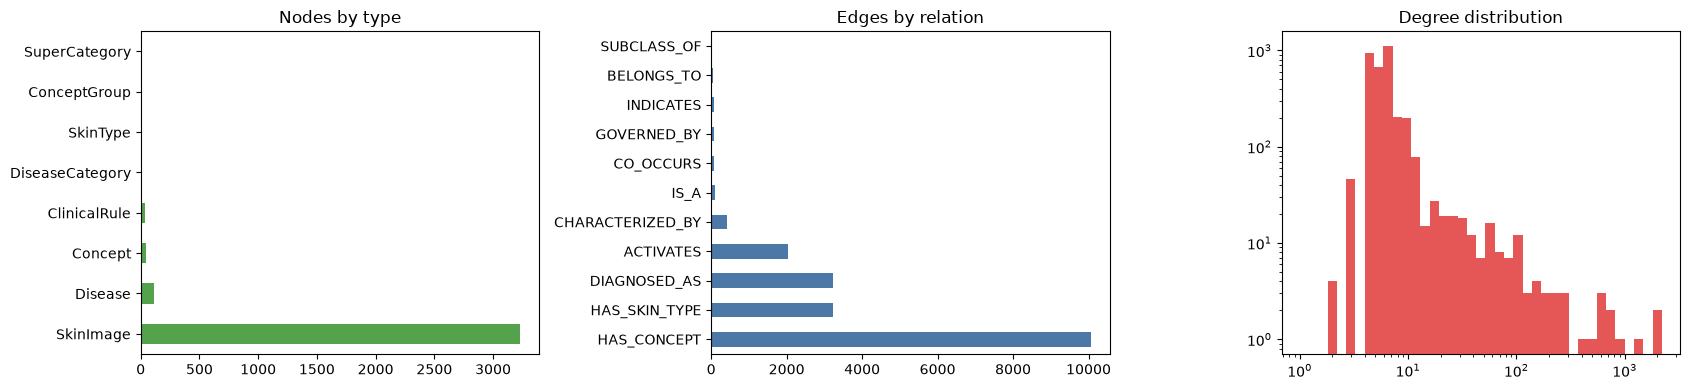

In [10]:
nt = pd.Series(nx.get_node_attributes(G, "ntype")).value_counts()
et = pd.Series([d["rel"] for *_, d in G.edges(data=True)]).value_counts()
U = nx.Graph(G)
lcc = max(nx.connected_components(U), key=len)
stats = {
    "nodes": G.number_of_nodes(), "edges": G.number_of_edges(),
    "node types": len(nt), "relation types": len(et),
    "expert rules": int((rules_df.origin == "expert").sum()), "mined rules": int((rules_df.origin == "mined").sum()),
    "density": nx.density(G), "LCC ratio": len(lcc) / U.number_of_nodes(),
    "avg degree": 2 * G.number_of_edges() / G.number_of_nodes(),
}
display(pd.Series(stats, name="DermKG").to_frame())
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
nt.plot.barh(ax=axes[0], color="#54a24b", title="Nodes by type")
et.plot.barh(ax=axes[1], color="#4c78a8", title="Edges by relation")
deg = pd.Series(dict(G.degree()))
axes[2].hist(deg.values, bins=np.logspace(0, np.log10(deg.max() + 1), 40), color="#e45756")
axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].set_title("Degree distribution")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "graph_stats.png"), dpi=200); plt.show()
json.dump({k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in stats.items()},
          open(os.path.join(OUT_DIR, "graph_stats.json"), "w"), indent=1)

## 10. Reasoning chains and rule coverage

For image $i$ and disease $d$, the chain score sums the weights of activated rules that indicate $d$ (directly or through its category):

$$\mathrm{CS}(i,d)=\sum_{r\in\mathcal{R}(i)} w_r\,\mathbb{1}[d\in T_r],\qquad w_r\in\{3,2,1,0\}$$

Coverage statistics below describe the graph; they are not a classifier evaluation.

In [12]:
W = np.array([RULE_WEIGHT[r["strength"]] for r in RULES], dtype=float)
T = np.zeros((len(RULES), len(DISEASES)))
d_idx = {d: i for i, d in enumerate(DISEASES)}
for k, r in enumerate(RULES):
    for d in r["targets"]:
        T[k, d_idx[d]] = 1
CS = (ACT * W) @ T                                    # images x diseases
df["n_rules"] = ACT.sum(1)
df["n_rules_expert"] = ACT[:, rules_df.origin.values == "expert"].sum(1)
df["chain_score_true"] = CS[np.arange(len(df)), df["label"].map(d_idx).values]
df["true_in_chain"] = df["chain_score_true"] > 0

cov = df.groupby("split").agg(
    avg_rules=("n_rules", "mean"), avg_expert_rules=("n_rules_expert", "mean"),
    covered_ge1=("n_rules", lambda s: (s >= 1).mean()), covered_ge3=("n_rules", lambda s: (s >= 3).mean()),
    true_disease_in_chain=("true_in_chain", "mean"), avg_chain_score_true=("chain_score_true", "mean"))
display(cov.round(3).T)

expert_cov = df.groupby("nine_partition_label")["n_rules_expert"].apply(lambda s: (s > 0).mean()).sort_values()
print("Share of images activating at least one expert rule, by category:")
print(expert_cov.round(2).to_string())

split,test,train,val
avg_rules,0.597,0.629,0.676
avg_expert_rules,0.512,0.528,0.590
covered_ge1,0.447,0.456,0.500
covered_ge3,0.026,0.038,0.037
true_disease_in_chain,0.199,0.189,0.204
avg_chain_score_true,0.577,0.617,0.617


Share of images activating at least one expert rule, by category:
nine_partition_label
benign dermal                   0.32
benign epidermal                0.36
genodermatoses                  0.38
benign melanocyte               0.43
inflammatory                    0.45
malignant cutaneous lymphoma    0.45
malignant dermal                0.50
malignant melanoma              0.52
malignant epidermal             0.53


## 11. Visualization (pyvis)

HTML files are saved under `figures/` with the JavaScript inlined, so they open offline in any browser.

In [13]:
COLOR = {"SkinImage": "#9e9e9e", "Concept": "#4c78a8", "ConceptGroup": "#72b7b2", "Disease": "#e45756",
         "DiseaseCategory": "#f58518", "SuperCategory": "#b279a2", "SkinType": "#eeca3b", "ClinicalRule": "#54a24b"}
SHAPE = {"ClinicalRule": "diamond", "SkinImage": "square"}


def to_pyvis(H, path, height="800px", physics=True):
    net = Network(height=height, width="100%", directed=True, cdn_resources="in_line", bgcolor="#ffffff")
    for n, a in H.nodes(data=True):
        t = a["ntype"]
        title = "\n".join(f"{k}: {v}" for k, v in a.items())
        net.add_node(n, label=str(a.get("name", n))[:40], color=COLOR[t], shape=SHAPE.get(t, "dot"),
                     title=title, size=a.get("_size", 18))
    for u, v, a in H.edges(data=True):
        net.add_edge(u, v, title=a["rel"], label=a.get("_label", ""), width=a.get("_width", 1.5),
                     color=a.get("_color", "#bbbbbb"))
    net.toggle_physics(physics)
    net.save_graph(path)
    print("saved", path)

### 11.1 Schema

In [14]:
S = nx.MultiDiGraph()
for t in COLOR:
    S.add_node(t, ntype=t, name=f"{t} ({int(nt.get(t, 0))})", _size=30)
schema_edges = [("SkinImage", "Concept", "HAS_CONCEPT"), ("SkinImage", "SkinType", "HAS_SKIN_TYPE"),
                ("SkinImage", "Disease", "DIAGNOSED_AS"), ("Concept", "ConceptGroup", "BELONGS_TO"),
                ("Disease", "DiseaseCategory", "IS_A"), ("DiseaseCategory", "SuperCategory", "SUBCLASS_OF"),
                ("Disease", "Concept", "CHARACTERIZED_BY"), ("Concept", "Concept", "CO_OCCURS"),
                ("Concept", "ClinicalRule", "GOVERNED_BY"), ("ClinicalRule", "Disease", "INDICATES"),
                ("SkinImage", "ClinicalRule", "ACTIVATES")]
for u, v, r in schema_edges:
    S.add_edge(u, v, rel=r, _label=f"{r} ({int(et.get(r, 0))})", _width=2)
to_pyvis(S, os.path.join(FIG_DIR, "schema.html"), height="650px")

saved data/dermkg\figures\schema.html


### 11.2 Single-case reasoning chain

Image, its concepts, the rules they activate, the indicated diseases (chain score as edge label), and the true label. Pick any test image by changing `CASE_IDX`.

In [15]:
top1 = np.array(DISEASES)[CS.argmax(1)]
test_ids = df.index[(df.split == "test") & (df.n_rules_expert >= 2) & (top1 == df["label"].values)].tolist()
test_ids = test_ids or df.index[(df.split == "test") & df.true_in_chain].tolist()
CASE_IDX = test_ids[0] if test_ids else df.index[df.split == "test"][0]


def case_graph(i):
    r = df.loc[i]
    img = f"Image:{r.md5}"
    nodes = {img, f"Disease:{r.label}", f"SkinType:{r.skin_type}"}
    concepts = [c for c in CONCEPTS if r[c] == 1]
    nodes |= {f"Concept:{c}" for c in concepts}
    act = [RULES[k] for k in np.flatnonzero(ACT[i])]
    nodes |= {f"Rule:{x['rule_id']}" for x in act}
    top = np.argsort(-CS[i])[:5]
    nodes |= {f"Disease:{DISEASES[k]}" for k in top if CS[i, k] > 0}
    H = nx.MultiDiGraph()
    for n in nodes:
        H.add_node(n, **G.nodes[n])
    H.nodes[f"Disease:{r.label}"]["_size"] = 32
    H.nodes[f"Disease:{r.label}"]["name"] = f"[TRUE] {r.label}"
    for c in concepts:
        H.add_edge(img, f"Concept:{c}", rel="HAS_CONCEPT")
    H.add_edge(img, f"SkinType:{r.skin_type}", rel="HAS_SKIN_TYPE")
    for x in act:
        rn = f"Rule:{x['rule_id']}"
        H.add_edge(img, rn, rel="ACTIVATES", _color="#54a24b")
        for clause in x["premise"]:
            for c in clause:
                if c in concepts:
                    H.add_edge(f"Concept:{c}", rn, rel="GOVERNED_BY")
        for d in x["targets"]:
            if f"Disease:{d}" in H:
                H.add_edge(rn, f"Disease:{d}", rel="INDICATES", _label=x["strength"],
                           _width=1 + RULE_WEIGHT[x["strength"]], _color="#e45756")
    for k in top:
        if CS[i, k] > 0:
            H.nodes[f"Disease:{DISEASES[k]}"]["name"] = H.nodes[f"Disease:{DISEASES[k]}"]["name"] + f" | CS={CS[i, k]:.0f}"
    return H, r, act, top


H, r, act, top = case_graph(CASE_IDX)
print(f"case {r.md5[:8]} | true: {r.label} | skin type {r.skin_type}")
print("concepts:", [c for c in CONCEPTS if r[c] == 1])
for x in act:
    print(f"  {x['rule_id']} [{x['strength']}] {x['name']}")
print("top chain scores:", [(DISEASES[k], CS[CASE_IDX, k]) for k in top if CS[CASE_IDX, k] > 0])
to_pyvis(H, os.path.join(FIG_DIR, f"case_{r.md5[:8]}.html"), height="700px")

case 3c872d24 | true: acne | skin type FST-1
concepts: ['Papule', 'Plaque', 'Pustule', 'Crust', 'Scale', 'Erythema']
  R08 [moderate] Erythematous scaly plaque -> papulosquamous disease
  R09 [strong] Pustule -> pustular / follicular disease
top chain scores: [('acne', np.float64(3.0)), ('acne vulgaris', np.float64(3.0)), ('folliculitis', np.float64(3.0)), ('perioral dermatitis', np.float64(3.0)), ('pustular psoriasis', np.float64(3.0))]
saved data/dermkg\figures\case_3c872d24.html


### 11.3 Knowledge overview (disease level)

Disease, concept, category and rule layers without image nodes. `OVERVIEW_SUPER` limits it to one super-category for readability (set to `None` for all).

In [16]:
OVERVIEW_SUPER = "malignant"

keep = {n for n, a in G.nodes(data=True) if a["ntype"] in ("Concept", "ConceptGroup", "SuperCategory")}
for d in DISEASES:
    if OVERVIEW_SUPER is None or CAT2SUP[D2CAT[d]] == OVERVIEW_SUPER:
        keep |= {f"Disease:{d}", f"Category:{D2CAT[d]}"}
rule_keep = {f"Rule:{x['rule_id']}" for x in RULES if x["origin"] == "expert"
             and any(f"Disease:{d}" in keep for d in x["targets"])}
keep |= rule_keep
H = nx.MultiDiGraph()
for u, v, a in G.edges(data=True):
    if u in keep and v in keep and a["rel"] in ("CHARACTERIZED_BY", "IS_A", "SUBCLASS_OF", "BELONGS_TO",
                                                 "GOVERNED_BY", "INDICATES"):
        for n in (u, v):
            if n not in H:
                H.add_node(n, **G.nodes[n])
        w = a["weight"] * 4 if a["rel"] == "CHARACTERIZED_BY" else 1.5
        H.add_edge(u, v, rel=a["rel"], _width=w)
print(H)
to_pyvis(H, os.path.join(FIG_DIR, f"overview_{OVERVIEW_SUPER or 'all'}.html"), height="900px")

MultiDiGraph with 76 nodes and 147 edges
saved data/dermkg\figures\overview_malignant.html


### 11.4 Disease to concept heatmap (static, for the paper)

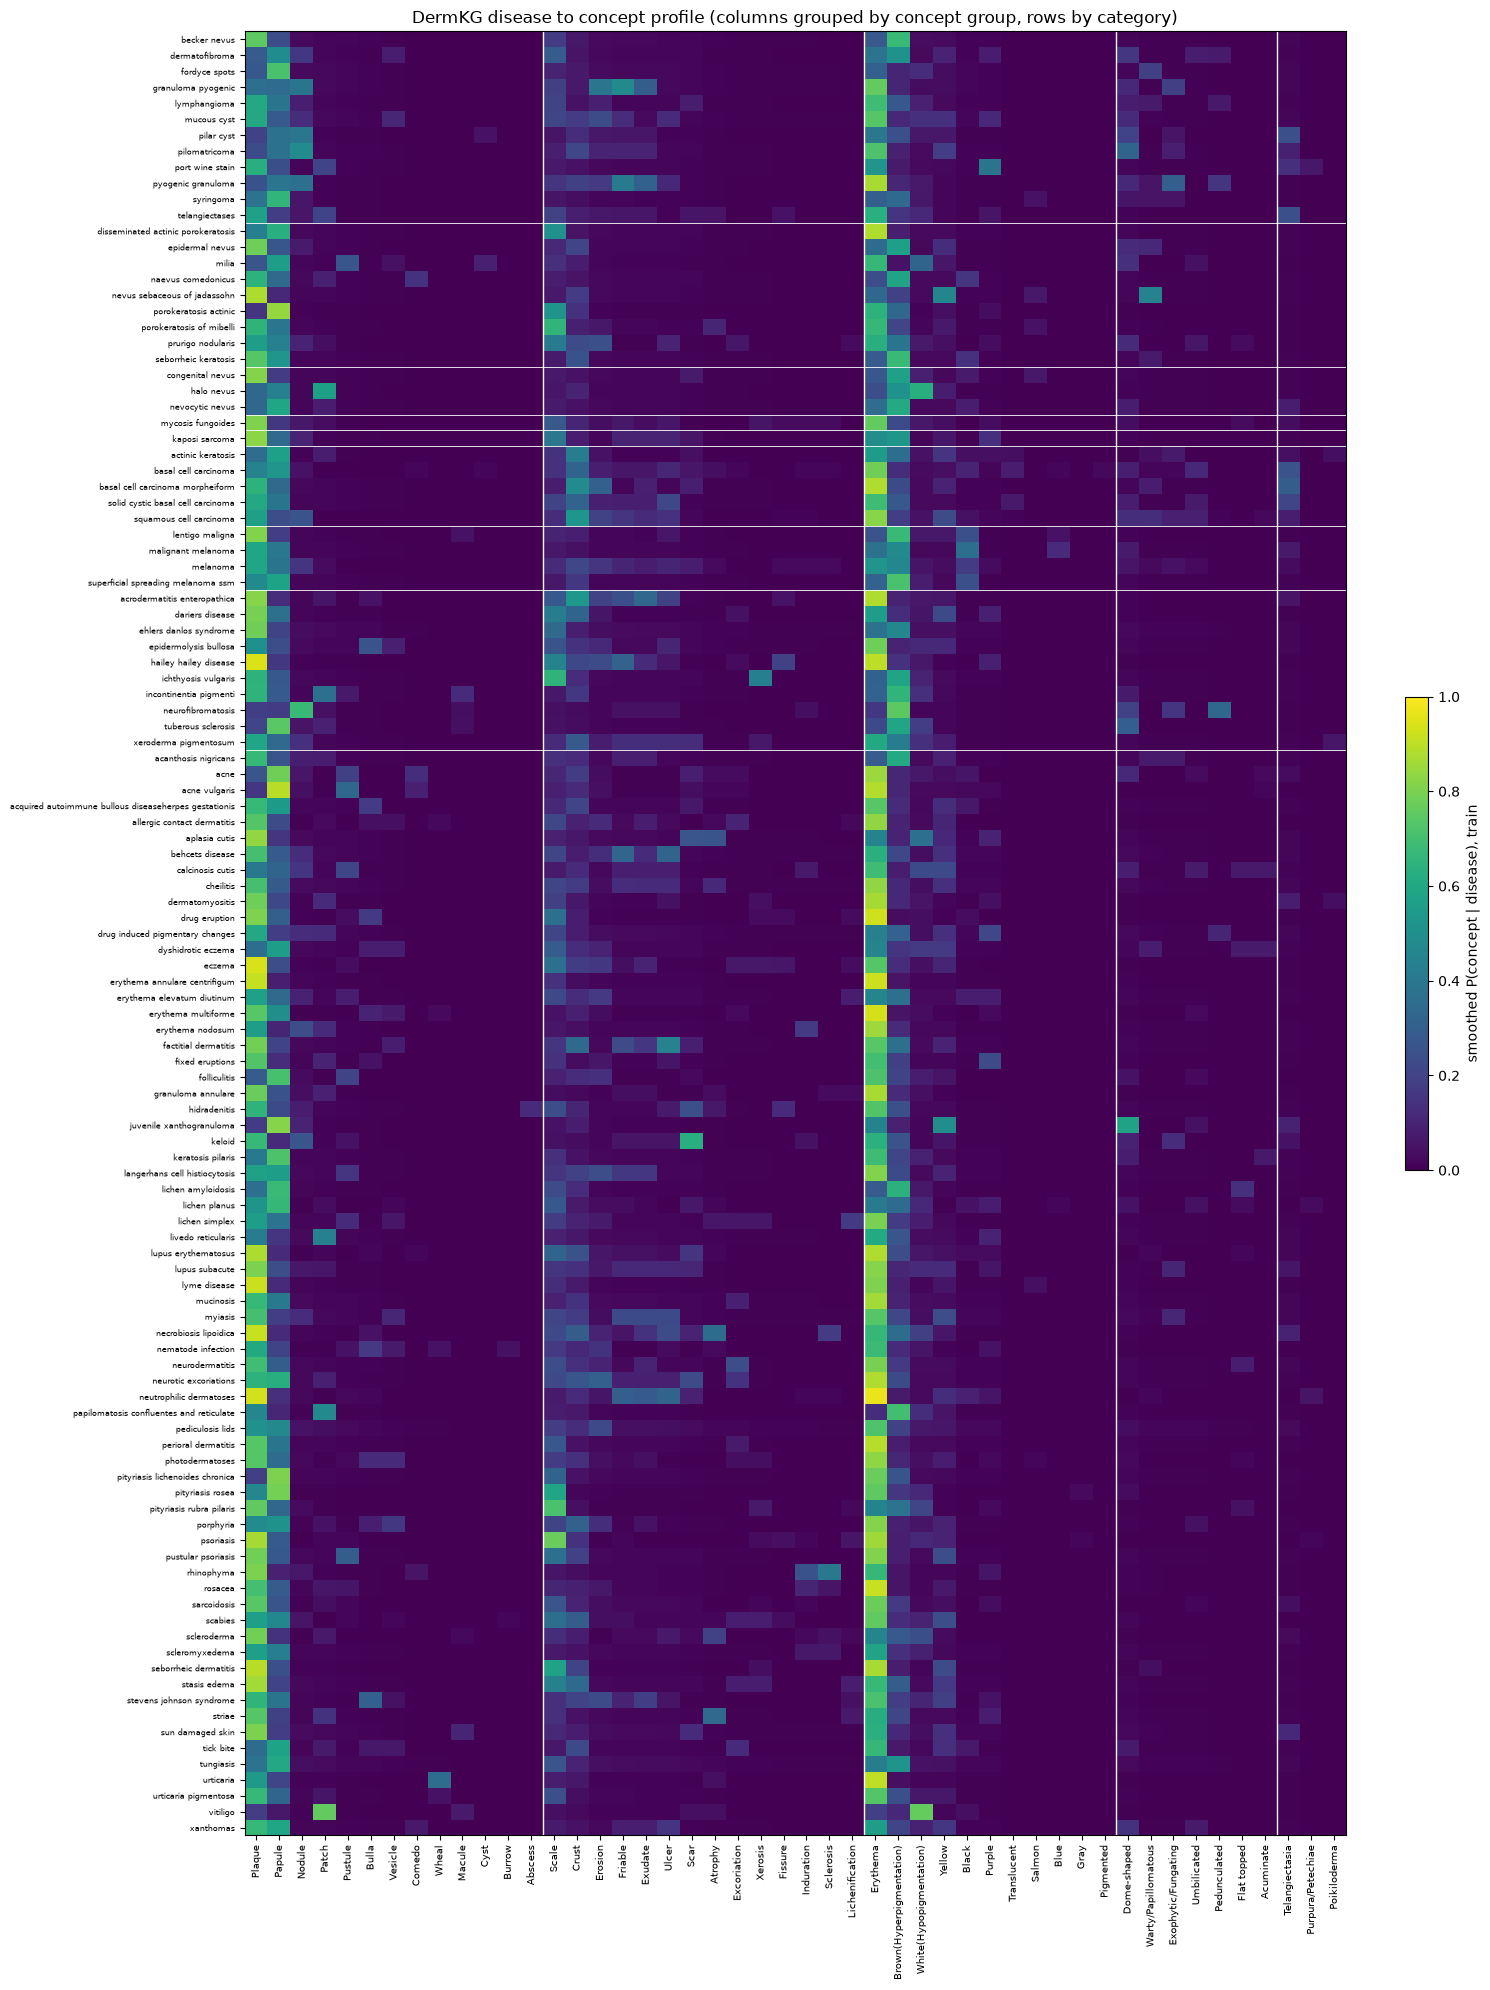

In [17]:
order_d = sorted(DISEASES, key=lambda d: (CAT2SUP[D2CAT[d]], D2CAT[d], d))
order_c = [c for g in CONCEPT_GROUPS for c in sorted(CONCEPT_GROUPS[g], key=lambda c: -p_c[c])]
M = p_dc.loc[order_d, order_c]
fig, ax = plt.subplots(figsize=(15, 20))
im = ax.imshow(M.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(order_c))); ax.set_xticklabels(order_c, rotation=90, fontsize=7)
ax.set_yticks(range(len(order_d))); ax.set_yticklabels(order_d, fontsize=6)
b = np.cumsum([len(CONCEPT_GROUPS[g]) for g in CONCEPT_GROUPS])[:-1]
for x in b:
    ax.axvline(x - 0.5, color="white", lw=1)
cb = [i for i in range(1, len(order_d)) if D2CAT[order_d[i]] != D2CAT[order_d[i - 1]]]
for y in cb:
    ax.axhline(y - 0.5, color="white", lw=0.6)
plt.colorbar(im, ax=ax, fraction=0.02, label="smoothed P(concept | disease), train")
ax.set_title("DermKG disease to concept profile (columns grouped by concept group, rows by category)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "disease_concept_heatmap.png"), dpi=200); plt.show()

## 12. Diagnostics: indistinguishable diseases

Diseases whose binary `CHARACTERIZED_BY` concept sets are identical cannot be separated by the graph structure alone. This motivates using the weighted profile and, later, external knowledge.

In [18]:
sig = {d: frozenset(v.split(":", 1)[1] for _, v, a in G.out_edges(f"Disease:{d}", data=True)
                     if a["rel"] == "CHARACTERIZED_BY") for d in DISEASES}
groups = defaultdict(list)
for d, s in sig.items():
    groups[s].append(d)
dup = {s: ds for s, ds in groups.items() if len(ds) > 1}
print(f"diseases sharing an identical concept set: {sum(map(len, dup.values()))} / {len(DISEASES)} in {len(dup)} groups")
for s, ds in sorted(dup.items(), key=lambda x: -len(x[1])):
    print(f"  {sorted(s)} -> {ds}")
print("diseases with no CHARACTERIZED_BY edge:", [d for d, s in sig.items() if not s])

diseases sharing an identical concept set: 29 / 113 in 10 groups
  ['Erythema', 'Plaque'] -> ['cheilitis', 'dermatomyositis', 'erythema annulare centrifigum', 'granuloma annulare', 'lupus subacute', 'lyme disease', 'rosacea']
  ['Brown(Hyperpigmentation)', 'Plaque'] -> ['acanthosis nigricans', 'becker nevus', 'congenital nevus', 'naevus comedonicus']
  ['Erythema', 'Plaque', 'Scale'] -> ['eczema', 'mycosis fungoides', 'sarcoidosis']
  ['Brown(Hyperpigmentation)', 'Papule'] -> ['nevocytic nevus', 'syringoma', 'tungiasis']
  ['Comedo', 'Erythema', 'Papule', 'Pustule'] -> ['acne', 'acne vulgaris']
  ['Brown(Hyperpigmentation)', 'Papule', 'Scale'] -> ['dermatofibroma', 'porokeratosis actinic']
  ['Erythema', 'Papule', 'Scale'] -> ['disseminated actinic porokeratosis', 'pityriasis rosea']
  ['Papule'] -> ['fordyce spots', 'scleromyxedema']
  ['Brown(Hyperpigmentation)', 'Patch'] -> ['livedo reticularis', 'papilomatosis confluentes and reticulate']
  ['Black', 'Brown(Hyperpigmentation)', 'Pa

## 13. Export

- `triples_full.csv`: every edge as (head, relation, tail), with split for `DIAGNOSED_AS`
- `triples_infer.csv`: inference graph, val/test `DIAGNOSED_AS` removed
- `labels.csv`: md5, disease, split (targets for val/test evaluation)
- `nodes.csv`, `dermkg.graphml`: for Gephi / Cytoscape
- `dermkg_hetero.npz`: per-relation edge index for PyTorch Geometric `HeteroData`

In [19]:
rows = [(u, a["rel"], v, a.get("weight", 1.0), a.get("split", "")) for u, v, a in G.edges(data=True)]
tri = pd.DataFrame(rows, columns=["head", "relation", "tail", "weight", "split"])
tri.to_csv(os.path.join(OUT_DIR, "triples_full.csv"), index=False)
leak = (tri.relation == "DIAGNOSED_AS") & tri.split.isin(["val", "test"])
tri_inf = tri[~leak]
tri_inf.to_csv(os.path.join(OUT_DIR, "triples_infer.csv"), index=False)
df[["md5", "label", "nine_partition_label", "three_partition_label", "skin_type", "split"]].to_csv(
    os.path.join(OUT_DIR, "labels.csv"), index=False)

nodes = pd.DataFrame([{"id": n, **a} for n, a in G.nodes(data=True)])
nodes.to_csv(os.path.join(OUT_DIR, "nodes.csv"), index=False)
Gi = nx.MultiDiGraph(); Gi.add_nodes_from(G.nodes(data=True))
Gi.add_edges_from((u, v, a) for u, v, a in G.edges(data=True)
                  if not (a["rel"] == "DIAGNOSED_AS" and a.get("split") in ("val", "test")))
nx.write_graphml(nx.DiGraph(Gi), os.path.join(OUT_DIR, "dermkg.graphml"))

# heterogeneous arrays: local index per node type
local = {}
for t, g in nodes.groupby("ntype"):
    for i, n in enumerate(g["id"]):
        local[n] = (t, i)
arrays = {f"names__{t}": np.array(g["id"].tolist(), dtype=str) for t, g in nodes.groupby("ntype")}
for (rel), g in tri_inf.groupby("relation"):
    for (ht, tt), gg in g.groupby([g["head"].map(lambda n: local[n][0]), g["tail"].map(lambda n: local[n][0])]):
        key = f"{ht}__{rel}__{tt}"
        arrays[f"ei__{key}"] = np.stack([gg["head"].map(lambda n: local[n][1]).values,
                                         gg["tail"].map(lambda n: local[n][1]).values]).astype(np.int64)
        arrays[f"ew__{key}"] = gg["weight"].values.astype(np.float32)
img_rows = [local[f"Image:{m}"][1] for m in df["md5"]]
cm = np.zeros((len(df), len(CONCEPTS)), dtype=np.float32)
cm[img_rows] = df[CONCEPTS].values                                  # rows aligned with names__SkinImage
arrays["x__SkinImage"] = cm
arrays["concept_names"] = np.array(CONCEPTS, dtype=str)
np.savez_compressed(os.path.join(OUT_DIR, "dermkg_hetero.npz"), **arrays)

print("removed", int(leak.sum()), "val/test DIAGNOSED_AS edges from the inference graph")
print("edge sets:", sorted(k[4:] for k in arrays if k.startswith("ei__")))
print("files:", sorted(os.listdir(OUT_DIR)))

removed 971 val/test DIAGNOSED_AS edges from the inference graph
edge sets: ['ClinicalRule__INDICATES__Disease', 'ClinicalRule__INDICATES__DiseaseCategory', 'Concept__BELONGS_TO__ConceptGroup', 'Concept__CO_OCCURS__Concept', 'Concept__GOVERNED_BY__ClinicalRule', 'DiseaseCategory__SUBCLASS_OF__SuperCategory', 'Disease__CHARACTERIZED_BY__Concept', 'Disease__IS_A__DiseaseCategory', 'SkinImage__ACTIVATES__ClinicalRule', 'SkinImage__DIAGNOSED_AS__Disease', 'SkinImage__HAS_CONCEPT__Concept', 'SkinImage__HAS_SKIN_TYPE__SkinType']
files: ['clinical_rules.csv', 'dermkg.graphml', 'dermkg_hetero.npz', 'disease_concept_prob_train.csv', 'figures', 'graph_stats.json', 'labels.csv', 'nodes.csv', 'split.csv', 'triples_full.csv', 'triples_infer.csv']
